# 04 · Image data: packages (damaged vs intact) and produce (rotten vs fresh)

**Goal:** build clean, leak-free image datasets for the two photo models.

| Domain | Business question | Sources |
|---|---|---|
| packages | was the order damaged in shipping? | Kaggle *Industrial Quality Control of Packages* (3D renders) + Roboflow *Damaged vs good packages* (CC BY 4.0) + Roboflow *BoxCondition* (CC BY 4.0, added because of the bias described below) |
| produce | is the food spoiled? | Kaggle *Fruits fresh and rotten for classification* (apple, banana, orange) |

**Inputs:** `data/raw/images/` (from `scripts/download_data.py images`).
**Outputs:** `data/processed/images/<domain>/{train,val,test}/<class>/` (224×224 JPEG), a manifest CSV per domain, figures in `results/figures/`.

Steps (all in `src/data_images.py`): index → remove unreadable files → **remove copies** → resize to 224×224 → `splitfolders` 70/10/20 (seed 42) → final check that no val/test image is a copy of a train image.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))  # make `src` importable from notebooks/

import pandas as pd
from IPython.display import Image, display
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 200)

## 1. The hidden problem: copies

If a photo and an edited copy of it land in train and test, the model has effectively seen the
test answer and its accuracy is inflated. These datasets are full of copies: the fruit set was
"augmented" by its author (rotated by random angles, flipped, cropped, with noise added).

**Attempt 1: perceptual hash** (a 64-bit fingerprint, compared in all 8 orientations). It failed both ways:
- on the Kaggle package renders (one box on one conveyor belt) it calls *different* boxes copies,
  even a damaged and an intact one;
- on the fruits, copies rotated by e.g. 20° look as "different" as genuinely different fruits.

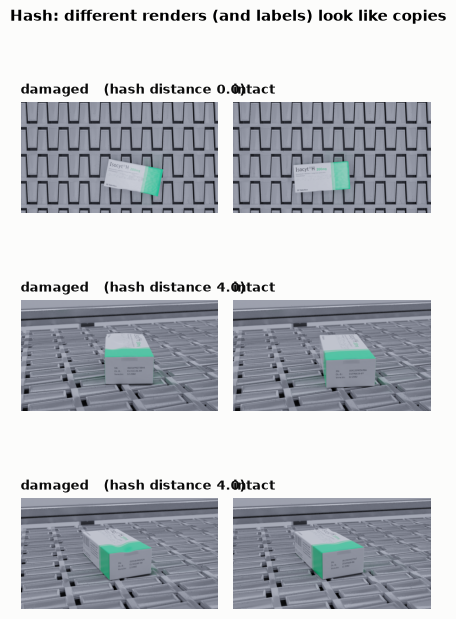

In [2]:
from src.data_images import index_domain, closest_pairs, plot_pairs
raw_packages = index_domain("packages")
kaggle_only = raw_packages[raw_packages["source"] == "packages_kaggle"]
pairs = closest_pairs(kaggle_only, method="phash", n=3, same_label=False, band=(0, 4))
plot_pairs(pairs, "Hash: different renders (and labels) look like copies", "image_phash_kaggle_lookalikes", "hash distance");

**Attempt 2: CLIP embeddings** grouped *similar-looking* fruits (hundreds of different bananas
into one group), not *copies*.

**Final method: SSCD** (Meta AI, MIT licence), a model trained specifically for **copy detection**.
It gives an image and its edited copies nearly the same fingerprint. Two images count as copies if
their SSCD similarity is ≥ 0.65 (chosen by looking at pairs: between 0.6 and 0.75 almost all pairs
are rotated/flipped/noised copies). The Kaggle renders get a stricter rule (only exact copies, ≥ 0.99),
because SSCD also sees every render of that one scene as similar.

Copies are grouped with "leader" clustering (each image joins a group only if it is directly similar
to that group's first image), so copy-of-a-copy chains can't merge different photos. One image per group is kept.

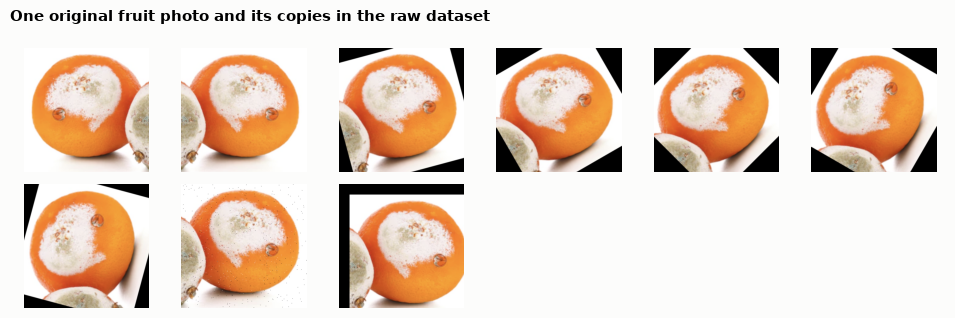

In [3]:
from src.data_images import copy_group_example, plot_images
raw_produce = index_domain("produce")
plot_images(copy_group_example(raw_produce), "One original fruit photo and its copies in the raw dataset", "image_produce_copy_group");

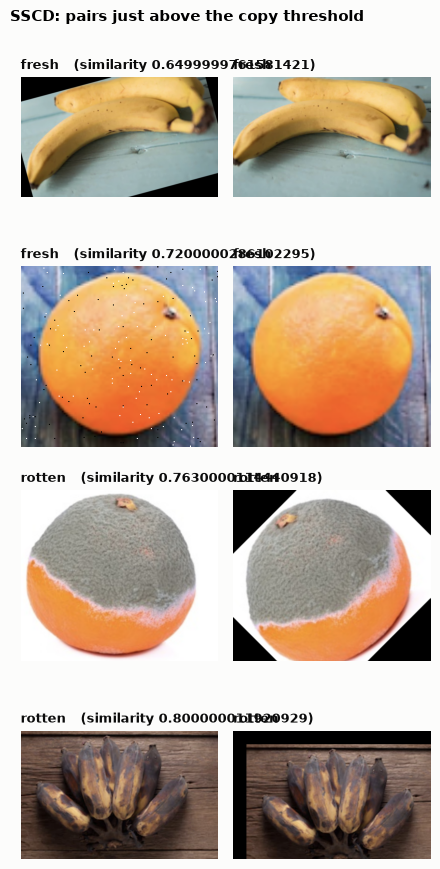

In [4]:
pairs = closest_pairs(raw_produce.sample(3000, random_state=42), method="sscd", n=4, band=(0.65, 0.8))
plot_pairs(pairs, "SSCD: pairs just above the copy threshold", "image_produce_sscd_pairs");

## 2. Packages: build the dataset

In [5]:
from src.data_images import build_image_dataset
packages = build_image_dataset("packages", verbose=False)
print("Raw images per source and class:"); display(packages["raw_counts"])
print("Unreadable files:", len(packages["broken"]))
print("Copies:", packages["duplicate_report"])
print("Val/test copies of train images found after the split (removed):", packages["cross_split_copies_removed"])
print("Final counts per source, class and split:"); display(packages["split_counts"])

Copying files: 0 files [00:00, ? files/s]

Copying files: 230 files [00:00, 2297.68 files/s]

Copying files: 520 files [00:00, 2648.38 files/s]

Copying files: 837 files [00:00, 2885.50 files/s]

Copying files: 1172 files [00:00, 3067.63 files/s]

...

Copying files: 2195 files [00:00, 3154.98 files/s]

Raw images per source and class:


label,damaged,intact,total
source,,,
packages_boxcondition,2329,1643,3972
packages_kaggle,200,200,400
packages_roboflow,256,325,581
total,2785,2168,4953


Unreadable files: 0
Copies: {'images': 4953, 'copy_groups': 1003, 'images_in_copy_groups': 3757, 'groups_across_sources': 80, 'groups_with_conflicting_labels': 4, 'kept': 2195, 'removed': 2758}
Val/test copies of train images found after the split (removed): 0
Final counts per source, class and split:


split                          train  val  test  total
source                label                           
packages_boxcondition damaged    453   62   135    650
                      intact     458   60   131    649
packages_kaggle       damaged    138   24    38    200
                      intact     149   18    33    200
packages_roboflow     damaged    142   18    38    198
                      intact     195   36    67    298
total                           1535  218   442   2195

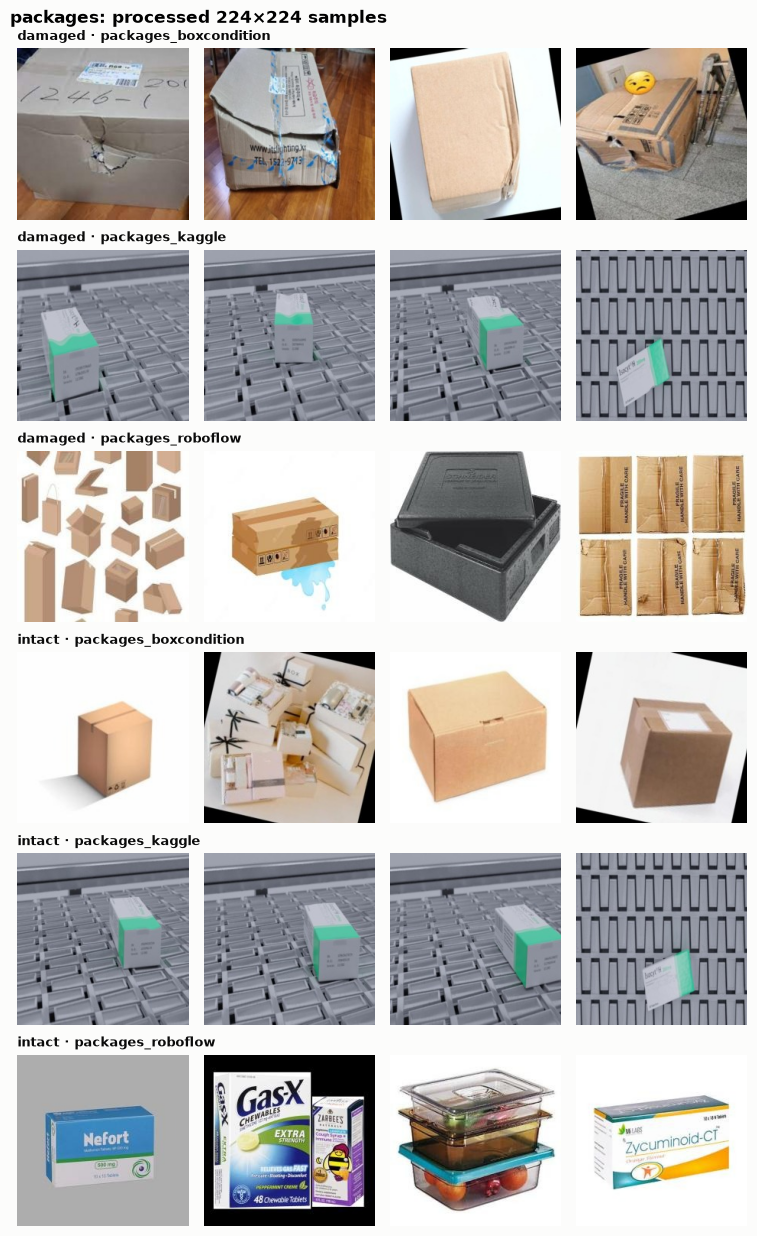

In [6]:
from src.data_images import plot_sample_grid
plot_sample_grid(packages["manifest"], "packages", group_col="source");

## 3. Produce: build the dataset

In [7]:
produce = build_image_dataset("produce", verbose=False)
print("Raw images per class:"); display(produce["raw_counts"])
print("Unreadable files:", len(produce["broken"]))
print("Copies:", produce["duplicate_report"])
print("Val/test copies of train images found after the split (removed):", produce["cross_split_copies_removed"])
print("Final counts per class and split:"); display(produce["split_counts"])
print("Images per fruit and class:"); display(produce["subtype_counts"])

Copying files: 0 files [00:00, ? files/s]

Copying files: 382 files [00:00, 3818.44 files/s]

Copying files: 764 files [00:00, 3480.96 files/s]

Copying files: 1115 files [00:00, 3313.35 files/s]

Copying files: 1511 files [00:00, 3551.33 files/s]

...

label,fresh,rotten,total
source,,,
produce_kaggle,5904,7695,13599
total,5904,7695,13599


Unreadable files: 0
Copies: {'images': 13599, 'copy_groups': 1884, 'images_in_copy_groups': 13253, 'groups_across_sources': 0, 'groups_with_conflicting_labels': 3, 'kept': 2227, 'removed': 11372}
Val/test copies of train images found after the split (removed): 0
Final counts per class and split:


split                  train  val  test  total
source         label                          
produce_kaggle fresh     651   93   186    930
               rotten    907  129   261   1297
total                   1558  222   447   2227

Images per fruit and class:


label,fresh,rotten
subtype,,
apple,268,482
banana,356,523
orange,306,292


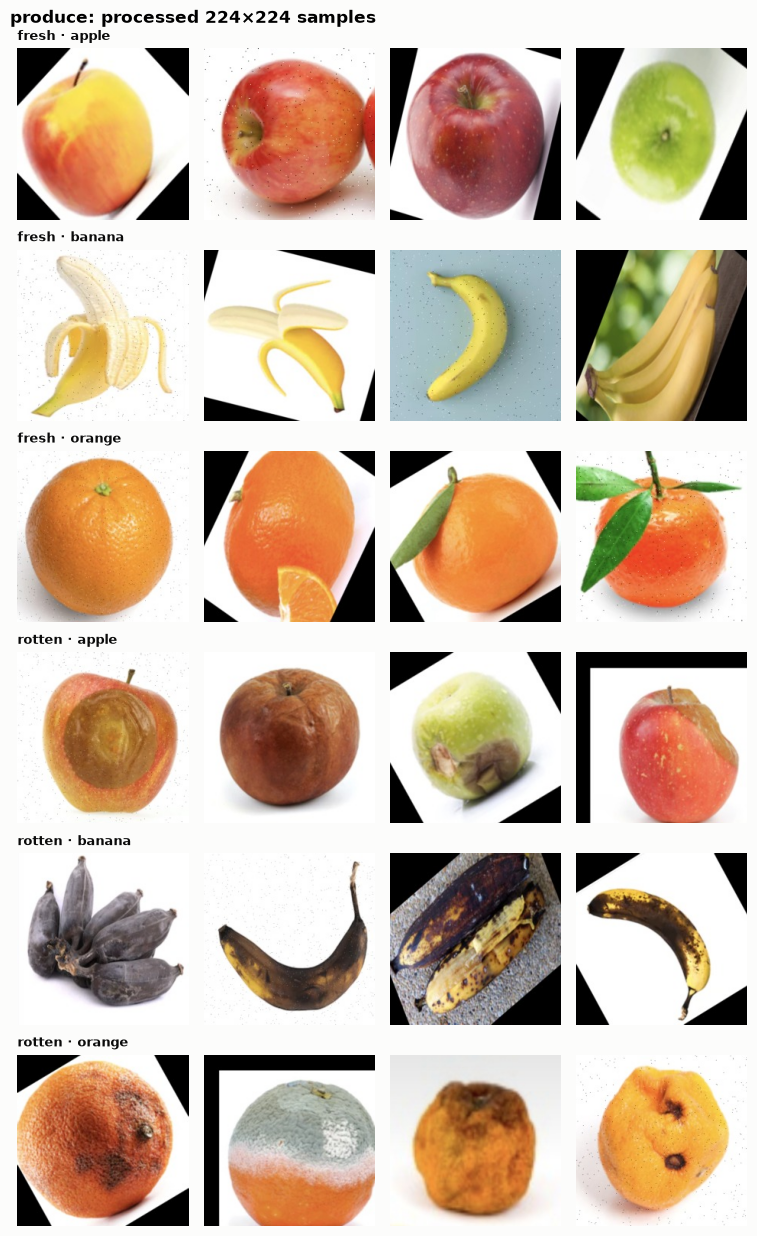

In [8]:
plot_sample_grid(produce["manifest"], "produce", group_col="subtype");

## Key findings

- **Copies were the main data problem.** 84% of the fruit images (11,372 of 13,599) were rotated, flipped,
  cropped or noised copies of other images. Kept in, copies of training photos would sit in the test set and
  inflate accuracy. After removing them: **2,227 different fruit photos** (930 fresh, 1,297 rotten), split
  1,558 / 222 / 447. The Kaggle zip also contained the whole dataset twice.
- **Choosing the right copy detector mattered:** the perceptual hash missed rotated copies and wrongly flagged
  different renders; CLIP grouped similar-looking fruits; SSCD, a model made for copy detection, separated copies
  from different photos (checked by eye at several similarity levels).
- **Packages: 4,953 → 2,195 images** (2,758 copies removed, mostly inside BoxCondition; 80 photos appeared in both
  Roboflow sets and were merged; 4 groups with conflicting labels dropped), split 1,535 / 218 / 442.
  No unreadable files in either domain, and no val/test image is a copy of a train image.
- **Dataset bias, and the fix:** in the first Roboflow set "intact" is mostly shiny product boxes on studio backgrounds
  and "damaged" mostly brown shipping cardboard (plus some label noise); the Kaggle packages are 3D renders of one box
  on one conveyor belt. A model could learn "brown cardboard = damaged". We therefore added **BoxCondition**, where both
  classes are brown cardboard boxes (650 damaged / 649 intact after copy removal), so the model has to learn the damage
  itself. Grad-CAM in the Colab image notebooks shows where the model looks, and results are reported per source.